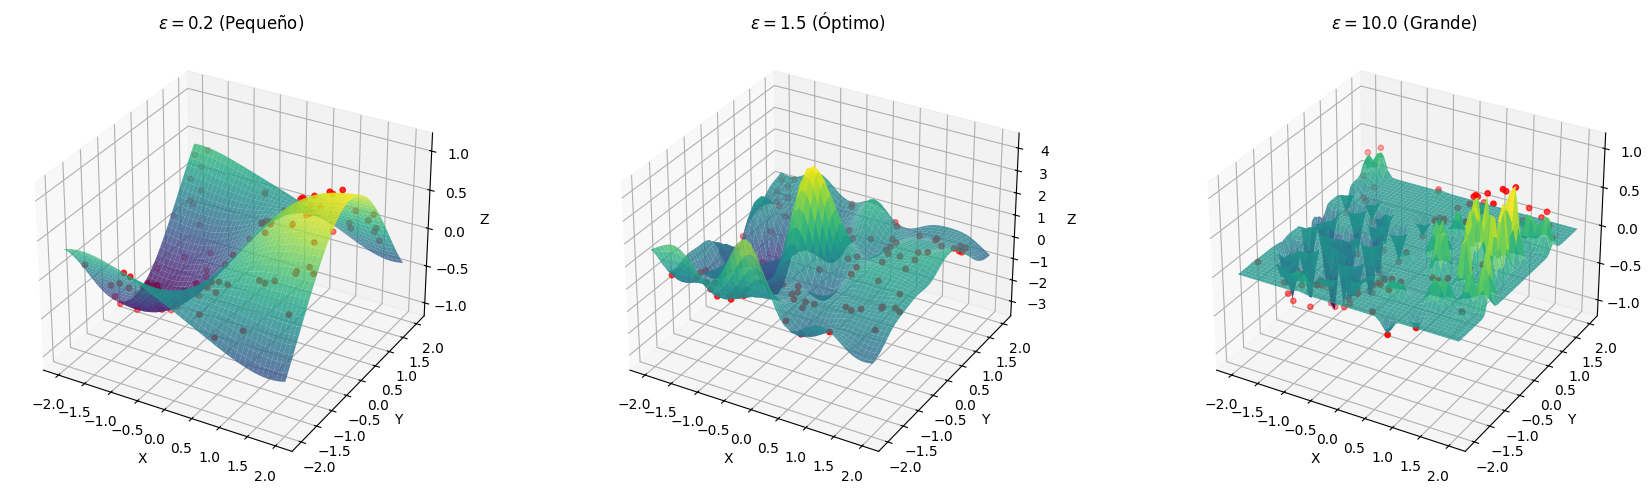

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


# Generación de Datos

np.random.seed(42) # Para reproducibilidad de los experimentos

# Crear 100 puntos aleatorios en el plano [-2, 2] x [-2, 2]
N_puntos = 100
X_train = np.random.uniform(-2, 2, size=(N_puntos, 2))
x_train = X_train[:, 0]
y_train = X_train[:, 1]

# Función no lineal: z = sin(x)*cos(y) + ruido gaussiano
ruido = np.random.normal(0, 0.05, N_puntos) # Ruido pequeño
z_train = np.sin(x_train) * np.cos(y_train) + ruido


# Implementación del Modelo RBF

def kernel_gaussiano(r, epsilon):
    """Evalúa el núcleo gaussiano dado un radio r y un parámetro de forma epsilon."""
    return np.exp(-(epsilon * r)**2)

def entrenar_rbf(X, z, epsilon, lambda_reg=1e-6):
    """Construye la matriz Phi y resuelve el sistema regularizado para obtener los pesos w."""
    n = X.shape[0]
    Phi = np.zeros((n, n))

    # Construcción de la matriz Phi calculando distancias euclídeas
    for i in range(n):
        for j in range(n):
            dist = np.linalg.norm(X[i] - X[j])
            Phi[i, j] = kernel_gaussiano(dist, epsilon)

    # Regularización de Tikhonov: (Phi + lambda * I) * w = z
    I = np.eye(n)
    w = np.linalg.solve(Phi + lambda_reg * I, z)
    return w

def predecir_rbf(X_train, w, X_test, epsilon):
    """Evalúa el modelo RBF en nuevos puntos X_test."""
    n_train = X_train.shape[0]
    n_test = X_test.shape[0]
    Phi_test = np.zeros((n_test, n_train))

    for i in range(n_test):
        for j in range(n_train):
            dist = np.linalg.norm(X_test[i] - X_train[j])
            Phi_test[i, j] = kernel_gaussiano(dist, epsilon)

    return Phi_test.dot(w)


# Visualización y Estudio de epsilon

# Malla fina de 50x50 para la predicción
x_grid = np.linspace(-2, 2, 50)
y_grid = np.linspace(-2, 2, 50)
X_test_x, X_test_y = np.meshgrid(x_grid, y_grid)
X_test_flat = np.c_[X_test_x.ravel(), X_test_y.ravel()]

# Parámetros a estudiar
epsilons = [0.2, 1.5, 10.0]  # Pequeño, óptimo, grande
lambda_reg = 1e-6 # Penalización para suavizar la superficie

fig = plt.figure(figsize=(18, 5))

for idx, eps in enumerate(epsilons):
    # Entrenar y predecir
    w = entrenar_rbf(X_train, z_train, eps, lambda_reg)
    z_pred_flat = predecir_rbf(X_train, w, X_test_flat, eps)
    Z_pred = z_pred_flat.reshape((50, 50))

    # Graficar
    ax = fig.add_subplot(1, 3, idx+1, projection='3d')
    superficie = ax.plot_surface(X_test_x, X_test_y, Z_pred, cmap='viridis', alpha=0.8)
    ax.scatter(x_train, y_train, z_train, c='r', marker='o', s=15, label='Datos con ruido')

    titulo = 'Pequeño' if idx == 0 else ('Óptimo' if idx == 1 else 'Grande')
    ax.set_title(rf'$\epsilon = {eps}$ ({titulo})')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

plt.tight_layout()
plt.show()